In [34]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, r2_score, mean_squared_error, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [35]:
np.random.seed(42)
n=1000

#Numric Features
age = np.random.randint(16, 60, n)
height_cm = np.random.randint(150, 200, n)
weight_kg = np.random.randint(45, 140, n)
sleep_hours = np.random.randint(3, 10 , n)
workout_days_per_week = np.random.randint(0, 7, n)
workout_duration_min = np.random.randint(10, 180, n)
cradio_days_per_week = np.random.randint(0, 7, n)
daily_calories = np.random.randint(1200, 4500, n)
protein_grams = np.random.randint(30, 260, n)
water_liters = np.random.randint(0.5, 7, n)
stress_level = np.random.randint(1, 10, n)
steps_per_day = np.random.randint(500, 25000, n)
program_consistency = np.random.randint(1, 10, n)
meal_quality = np.random.randint(1, 10, n)
motivation_level = np.random.randint(1, 10, n)

#Binary Features
gender_male = np.random.choice([0, 1], n)
gender_female = np.random.choice([0, 1], n)
smoker = np.random.choice([0, 1], n)
uses_supplements = np.random.choice([0, 1], n)
has_gym_membership = np.random.choice([0, 1], n)
injury_last_3_months = np.random.choice([0, 1], n)
tracks_macros = np.random.choice([0, 1], n)

#Categorical Features 
training_goal = np.random.choice(["fat_loss", "muscle_gain", "maintenance", "edurance"], n)
training_style = np.random.choice(["weights", "crossfit", "hiit", "mixed", "running"], n)
diet_type = np.random.choice(["normal", "hight_protein", "low_carb", "keto", "vegetrain"], n)
activity_level_job = np.random.choice(["desk", "mixed", "physical"], n)
sleep_quality = np.random.choice(["good", "ok", "poor"], n)
workout_time_pref = np.random.choice(["morning", "afternoon", "night"], n)

#Targets 
body_progress_percent = (
    program_consistency * 4 +
    meal_quality * 3 +
    motivation_level * 2.5 +
    sleep_hours * 2 +
    workout_days_per_week * 2.5 +
    cradio_days_per_week * 1.5 +
    protein_grams * 0.05 +
    water_liters * 1.5 +
    steps_per_day * 0.0003
    -
    stress_level * 3
    -
    smoker * 8
    -
    injury_last_3_months * 10
)

body_progress_precent = np.clip(body_progress_percent, 0, 100)

goal_achieved = (
    body_progress_percent >= 70
).astype(int)

In [36]:
df = pd.DataFrame({
    "age" : age,
    "height_cm" : height_cm,
    "weight_kg" : weight_kg,
    "sleep_hours" : sleep_hours,
    "workout_days_per_week" : workout_days_per_week,
    "workout_duration_min" : workout_duration_min,
    "cradio_days_per_week" : cradio_days_per_week,
    "daily_calories" : daily_calories,
    "protein_grams" : protein_grams,
    "water_liters" : water_liters,
    "stress_level" : stress_level,
    "steps_per_day" : steps_per_day,
    "program_consistency" : program_consistency,
    "meal_quality" : meal_quality,
    "motivation_level" : motivation_level,
    "gender_male" : gender_male,
    "gender_female" : gender_female,
    "smoker" : smoker,
    "uses_supplements" : uses_supplements,
    "has_gym_membership" : has_gym_membership,
    "injury_last_3_months" : injury_last_3_months,
    "tracks_macros" : tracks_macros,
    "training_goal" : training_goal,
    "training_style" : training_style,
    "diet_type" : diet_type,
    "activity_level_job" : activity_level_job,
    "sleep_quality" : sleep_quality,
    "workout_time_pref" : workout_time_pref,
    "body_progress_precent" : body_progress_precent,
    "goal_achieved" : goal_achieved
})
df.head()

,age,height_cm,weight_kg,sleep_hours,workout_days_per_week,workout_duration_min,cradio_days_per_week,daily_calories,protein_grams,water_liters,stress_level,steps_per_day,program_consistency,meal_quality,motivation_level,gender_male,gender_female,smoker,uses_supplements,has_gym_membership,injury_last_3_months,tracks_macros,training_goal,training_style,diet_type,activity_level_job,sleep_quality,workout_time_pref,body_progress_precent,goal_achieved
0,54,188,54,5,6,122,1,2391,137,2,4,3086,3,5,8,0,1,1,0,1,0,0,muscle_gain,weights,vegetrain,desk,ok,morning,64.2758,0
1,44,155,111,4,1,70,3,3868,55,5,1,3148,6,1,2,0,0,1,1,1,0,1,fat_loss,running,hight_protein,desk,poor,night,47.1944,0
2,30,155,58,5,6,146,3,2360,218,5,8,7813,2,5,7,1,1,0,0,0,1,1,fat_loss,running,low_carb,desk,ok,morning,56.7439,0
3,58,152,124,5,6,15,5,3401,194,3,5,18601,7,5,4,1,0,1,1,0,0,0,fat_loss,crossfit,keto,mixed,ok,night,82.2803,1
4,23,156,118,9,4,118,4,2611,180,0,1,13044,4,9,2,1,1,0,1,0,0,1,muscle_gain,hiit,keto,mixed,poor,morning,91.9132,1


In [37]:
num = ["age",
            "height_cm",
            "weight_kg",
            "sleep_hours",
            "workout_days_per_week",
            "workout_duration_min",
            "cradio_days_per_week",
            "daily_calories",
            "protein_grams",
            "water_liters",
            "stress_level",
            "steps_per_day",
            "program_consistency",
            "meal_quality",
            "motivation_level",
            "gender_male",
            "gender_female",
            "smoker",
            "uses_supplements",
            "has_gym_membership",
            "injury_last_3_months",
            "tracks_macros",
]
cat = ["training_goal",
       "training_style",
       "diet_type",
       "activity_level_job",
       "sleep_quality",
       "workout_time_pref"
]

In [38]:
pre = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"),cat)
    ]
)

In [39]:
ln = Pipeline(steps=[
    ("pre", pre),
    ("ln", LinearRegression())
])

In [40]:
ln

,steps,"[('pre', ...), ('ln', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [41]:
x = df.drop("body_progress_precent", axis=1)
y = df["body_progress_precent"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

ln.fit(x_train, y_train)
y_pr = ln.predict(x_test)

print("Linear Regrresion:\n")
print("MSE:", mean_squared_error(y_pr, y_test))
print("R2_score:", r2_score(y_pr, y_test))

Linear Regrresion:

MSE: 1.0950888374784085
R2_score: 0.9969044487252761


In [49]:
poly = Pipeline(steps=[
    ("pre", pre),
    ("poly", PolynomialFeatures(degree=3)),
    ('ln', LinearRegression())
])

In [50]:
poly

,steps,"[('pre', ...), ('poly', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [51]:
poly.fit(x_train,y_train)
y_pr1 = poly.predict(x_test)

print("Polynomial Features:\n")
print("MSE:", mean_squared_error(y_pr1, y_test))
print("R2_score:", r2_score(y_pr1, y_test))

Polynomial Features:

MSE: 16.142985588188658
R2_score: 0.939590189051323


In [52]:
log = Pipeline(steps=[
    ("pre", pre),
    ("log", LogisticRegression(max_iter=1000))
])

In [53]:
log

,steps,"[('pre', ...), ('log', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [60]:
x1 = df.drop("goal_achieved", axis=1)
y1 = df["goal_achieved"]

x_train1, x_test1, y_train1, y_test1 = train_test_split(x1, y1, test_size=0.3, random_state=42)

log.fit(x_train1, y_train1)
y_pr2 = log.predict(x_test1)

print("LogisticRegression:\n")
print("Accuracy:", accuracy_score(y_test1, y_pr2),"\n")
print("Confusion_Matrix:\n", confusion_matrix(y_test1, y_pr2),"\n")
print("Classification_Report:\n", classification_report(y_test1, y_pr2))

LogisticRegression:

Accuracy: 0.97 

Confusion_Matrix:
 [[189   4]
 [  5 102]] 

Classification_Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.98       193
           1       0.96      0.95      0.96       107

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300



In [57]:
knn = Pipeline(steps=[
    ("pre", pre),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

In [58]:
knn

,steps,"[('pre', ...), ('knn', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [62]:
knn.fit(x_train1, y_train1)
y_pr3 = knn.predict(x_test1)

print("KNN:\n")
print("Accuracy:", accuracy_score(y_test1, y_pr3),"\n")
print("Confusion_Matrix:\n", confusion_matrix(y_test1, y_pr3),"\n")
print("Classification_Report:\n", classification_report(y_test1, y_pr3))

KNN:

Accuracy: 0.7533333333333333 

Confusion_Matrix:
 [[169  24]
 [ 50  57]] 

Classification_Report:
               precision    recall  f1-score   support

           0       0.77      0.88      0.82       193
           1       0.70      0.53      0.61       107

    accuracy                           0.75       300
   macro avg       0.74      0.70      0.71       300
weighted avg       0.75      0.75      0.74       300



In [63]:
tree = Pipeline(steps=[
    ("pre", pre),
    ("tree", DecisionTreeClassifier())
])

In [64]:
tree.fit(x_train1, y_train1)
y_pr4 = tree.predict(x_test1)

print("Decision_Tree:\n")
print("Accurasy:", accuracy_score(y_test1, y_pr4),"\n")
print("Confusion_Matrix:\n", confusion_matrix(y_test1, y_pr4),"\n")
print("Classification_Report:\n", classification_report(y_test1, y_pr4))

Decision_Tree:

Accurasy: 0.8 

Confusion_Matrix:
 [[165  28]
 [ 32  75]] 

Classification_Report:
               precision    recall  f1-score   support

           0       0.84      0.85      0.85       193
           1       0.73      0.70      0.71       107

    accuracy                           0.80       300
   macro avg       0.78      0.78      0.78       300
weighted avg       0.80      0.80      0.80       300



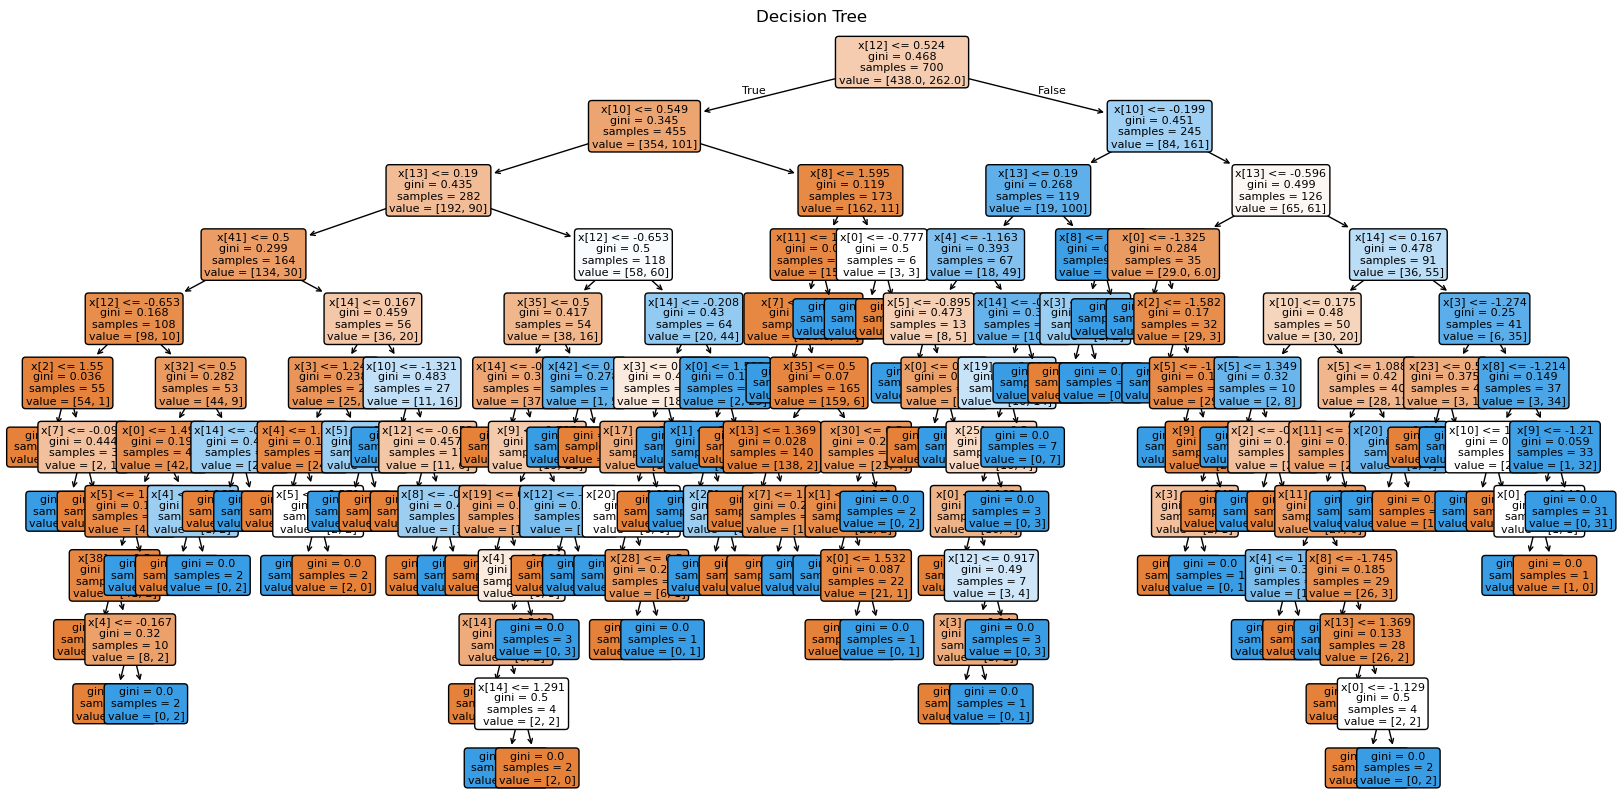

In [67]:
tree_model = tree.named_steps['tree']
plt.figure(figsize=(20,10))

plot_tree(
    tree_model,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree")
plt.show()